In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow version:", tf.__version__)

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

TensorFlow version: 2.21.0


In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
print("Train images:", x_train.shape, "| Train labels:", y_train.shape)
print("Test images :", x_test.shape, "| Test labels :", y_test.shape)

counts = pd.Series(np.bincount(y_train), index=CLASS_NAMES, name="images per class (train)")
print()
print(counts)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train images: (60000, 28, 28) | Train labels: (60000,)
Test images : (10000, 28, 28) | Test labels : (10000,)

T-shirt/top    6000
Trouser        6000
Pullover       6000
Dress          6000
Coat           6000
Sandal         6000
Shirt          6000
Sneaker        6000
Bag            6000
Ankle boot     6000
Name: images per class (train), dtype: int64


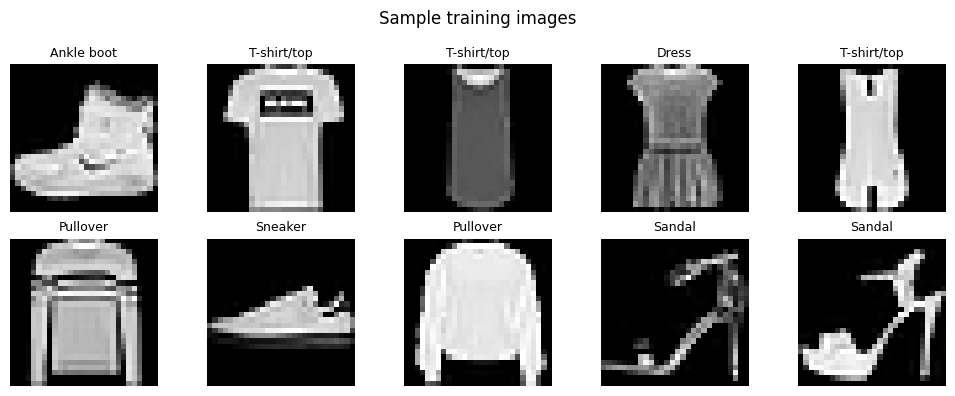

In [ ]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(CLASS_NAMES[y_train[i]], fontsize=9)
    plt.axis("off")
plt.suptitle("Sample training images")
plt.tight_layout()
plt.show()

In [ ]:
x_train = (x_train.astype("float32") / 255.0)[..., np.newaxis]
x_test = (x_test.astype("float32") / 255.0)[..., np.newaxis]
print("New train shape:", x_train.shape, "| pixel range:", x_train.min(), "to", x_train.max())

New train shape: (60000, 28, 28, 1) | pixel range: 0.0 to 1.0


In [ ]:
def build_baseline():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(10, activation="softmax"),
    ], name="baseline_cnn")
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

baseline = build_baseline()
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

hist_base = baseline.fit(x_train, y_train,
                         epochs=20, batch_size=64,
                         validation_split=0.1,
                         callbacks=[early_stop], verbose=2)

Epoch 1/20
844/844 - 17s - 20ms/step - accuracy: 0.8087 - loss: 0.5305 - val_accuracy: 0.8703 - val_loss: 0.3604
Epoch 2/20
844/844 - 3s - 4ms/step - accuracy: 0.8764 - loss: 0.3458 - val_accuracy: 0.8812 - val_loss: 0.3115
Epoch 3/20
844/844 - 3s - 4ms/step - accuracy: 0.8925 - loss: 0.2989 - val_accuracy: 0.8987 - val_loss: 0.2692
Epoch 4/20
844/844 - 3s - 4ms/step - accuracy: 0.9028 - loss: 0.2692 - val_accuracy: 0.9045 - val_loss: 0.2645
Epoch 5/20
844/844 - 4s - 4ms/step - accuracy: 0.9097 - loss: 0.2461 - val_accuracy: 0.9057 - val_loss: 0.2595
Epoch 6/20
844/844 - 6s - 7ms/step - accuracy: 0.9175 - loss: 0.2225 - val_accuracy: 0.9068 - val_loss: 0.2588
Epoch 7/20
844/844 - 9s - 11ms/step - accuracy: 0.9236 - loss: 0.2074 - val_accuracy: 0.9148 - val_loss: 0.2446
Epoch 8/20
844/844 - 5s - 6ms/step - accuracy: 0.9308 - loss: 0.1892 - val_accuracy: 0.9167 - val_loss: 0.2276
Epoch 9/20
844/844 - 4s - 4ms/step - accuracy: 0.9342 - loss: 0.1762 - val_accuracy: 0.9208 - val_loss: 0.228

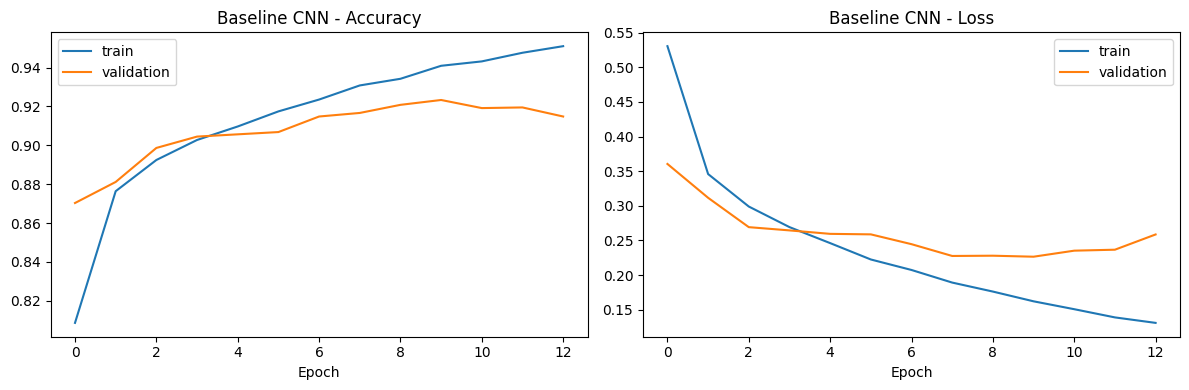

In [ ]:
def plot_curves(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history["accuracy"], label="train")
    ax[0].plot(history.history["val_accuracy"], label="validation")
    ax[0].set_title(title + " - Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(history.history["loss"], label="train")
    ax[1].plot(history.history["val_loss"], label="validation")
    ax[1].set_title(title + " - Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout()
    plt.show()

plot_curves(hist_base, "Baseline CNN")

In [ ]:
test_loss, test_acc = baseline.evaluate(x_test, y_test, verbose=0)
print(f"Baseline test accuracy: {test_acc:.4f} | test loss: {test_loss:.4f}")

y_pred = np.argmax(baseline.predict(x_test, verbose=0), axis=1)

Baseline test accuracy: 0.9181 | test loss: 0.2480


In [ ]:
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

              precision    recall  f1-score   support

 T-shirt/top      0.852     0.883     0.867      1000
     Trouser      0.997     0.976     0.986      1000
    Pullover      0.847     0.896     0.871      1000
       Dress      0.901     0.928     0.914      1000
        Coat      0.856     0.874     0.865      1000
      Sandal      0.987     0.989     0.988      1000
       Shirt      0.810     0.725     0.765      1000
     Sneaker      0.954     0.980     0.967      1000
         Bag      0.994     0.971     0.982      1000
  Ankle boot      0.984     0.959     0.971      1000

    accuracy                          0.918     10000
   macro avg      0.918     0.918     0.918     10000
weighted avg      0.918     0.918     0.918     10000



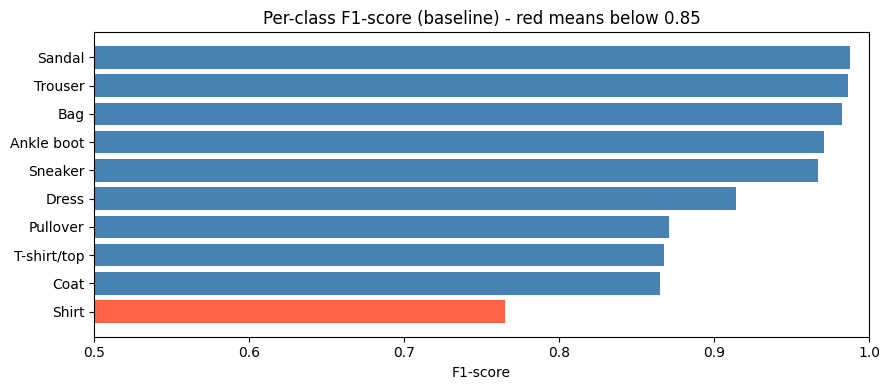

Weakest class: Shirt -> 0.765


In [ ]:
report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True)
f1 = pd.Series({c: report[c]["f1-score"] for c in CLASS_NAMES}).sort_values()

plt.figure(figsize=(9, 4))
colors = ["tomato" if v < 0.85 else "steelblue" for v in f1.values]
plt.barh(f1.index, f1.values, color=colors)
plt.xlim(0.5, 1.0)
plt.xlabel("F1-score")
plt.title("Per-class F1-score (baseline) - red means below 0.85")
plt.tight_layout()
plt.show()

print("Weakest class:", f1.index[0], "->", round(f1.iloc[0], 3))

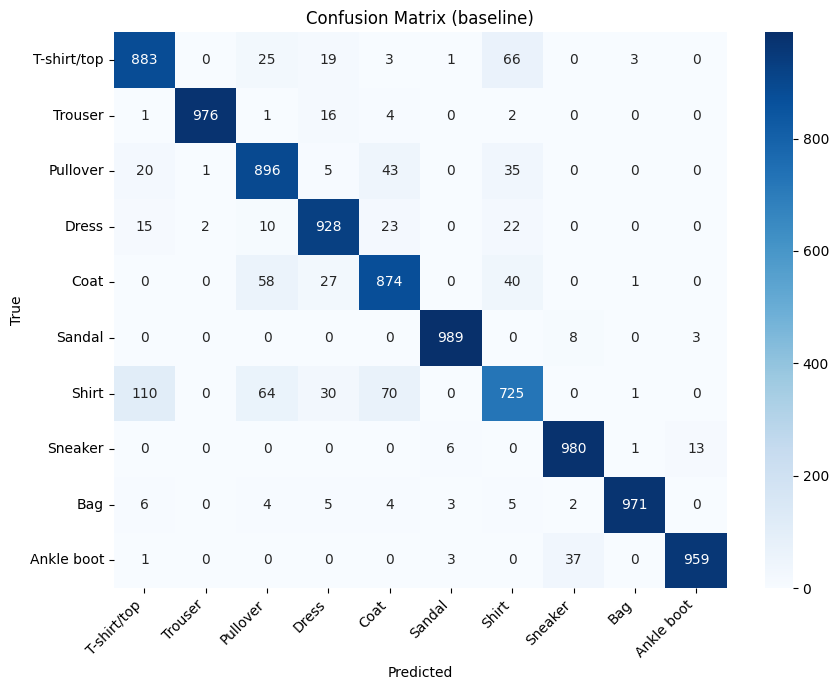

In [ ]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix (baseline)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
off = cm.copy()
np.fill_diagonal(off, 0)
order = np.argsort(off.ravel())[::-1][:5]
print("Top 5 confusions (true class -> predicted class):")
for flat in order:
    t, p = np.unravel_index(flat, off.shape)
    print(f"  {CLASS_NAMES[t]:12s} -> {CLASS_NAMES[p]:12s}: {off[t, p]} images")

Top 5 confusions (true class -> predicted class):
  Shirt        -> T-shirt/top : 110 images
  Shirt        -> Coat        : 70 images
  T-shirt/top  -> Shirt       : 66 images
  Shirt        -> Pullover    : 64 images
  Coat         -> Pullover    : 58 images


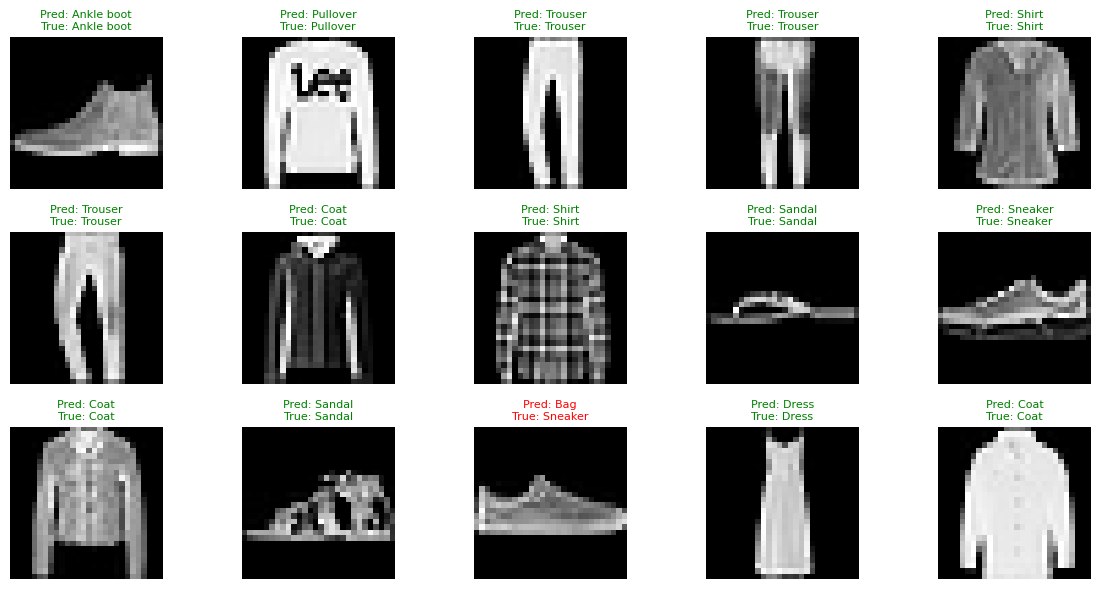

In [ ]:
plt.figure(figsize=(12, 6))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    ok = y_pred[i] == y_test[i]
    plt.title(f"Pred: {CLASS_NAMES[y_pred[i]]}\nTrue: {CLASS_NAMES[y_test[i]]}",
              color="green" if ok else "red", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

Misclassified: 819 out of 10000 test images


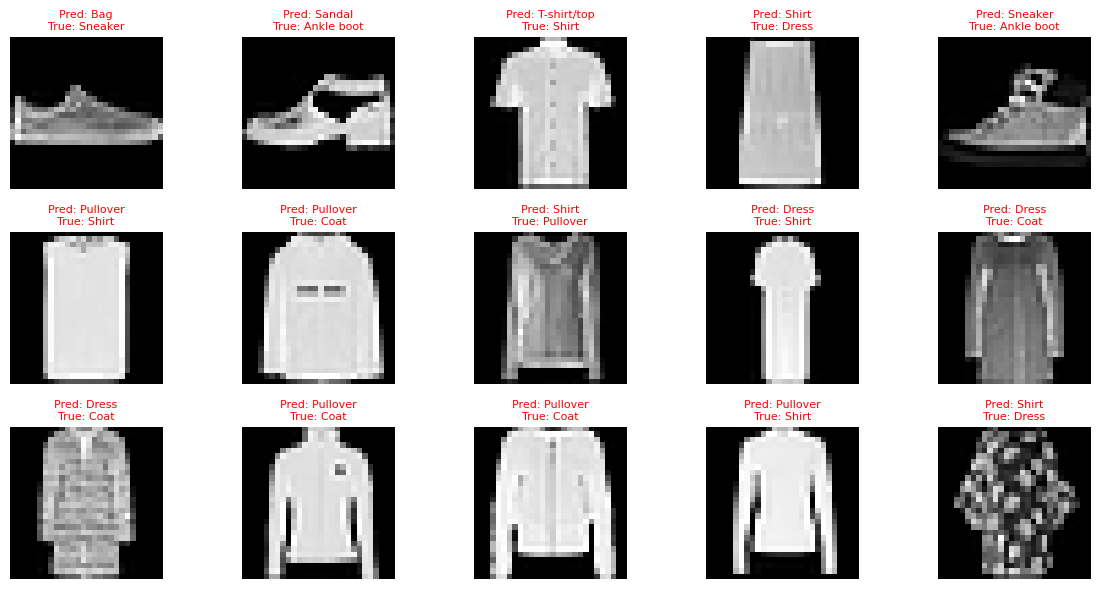

In [ ]:
wrong = np.where(y_pred != y_test)[0]
print(f"Misclassified: {len(wrong)} out of {len(y_test)} test images")

plt.figure(figsize=(12, 6))
for k, i in enumerate(wrong[:15]):
    plt.subplot(3, 5, k + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(f"Pred: {CLASS_NAMES[y_pred[i]]}\nTrue: {CLASS_NAMES[y_test[i]]}",
              color="red", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

Epoch 1/25
844/844 - 29s - 34ms/step - accuracy: 0.8447 - loss: 0.4439 - val_accuracy: 0.8980 - val_loss: 0.2846
Epoch 2/25
844/844 - 6s - 7ms/step - accuracy: 0.8963 - loss: 0.2938 - val_accuracy: 0.9130 - val_loss: 0.2393
Epoch 3/25
844/844 - 6s - 7ms/step - accuracy: 0.9070 - loss: 0.2567 - val_accuracy: 0.9137 - val_loss: 0.2399
Epoch 4/25
844/844 - 6s - 7ms/step - accuracy: 0.9189 - loss: 0.2292 - val_accuracy: 0.9130 - val_loss: 0.2454
Epoch 5/25
844/844 - 6s - 7ms/step - accuracy: 0.9198 - loss: 0.2204 - val_accuracy: 0.9233 - val_loss: 0.2152
Epoch 6/25
844/844 - 6s - 7ms/step - accuracy: 0.9267 - loss: 0.1994 - val_accuracy: 0.9312 - val_loss: 0.1925
Epoch 7/25
844/844 - 6s - 7ms/step - accuracy: 0.9300 - loss: 0.1901 - val_accuracy: 0.9347 - val_loss: 0.1796
Epoch 8/25
844/844 - 6s - 7ms/step - accuracy: 0.9341 - loss: 0.1805 - val_accuracy: 0.9320 - val_loss: 0.1857
Epoch 9/25
844/844 - 6s - 7ms/step - accuracy: 0.9384 - loss: 0.1680 - val_accuracy: 0.9300 - val_loss: 0.1884

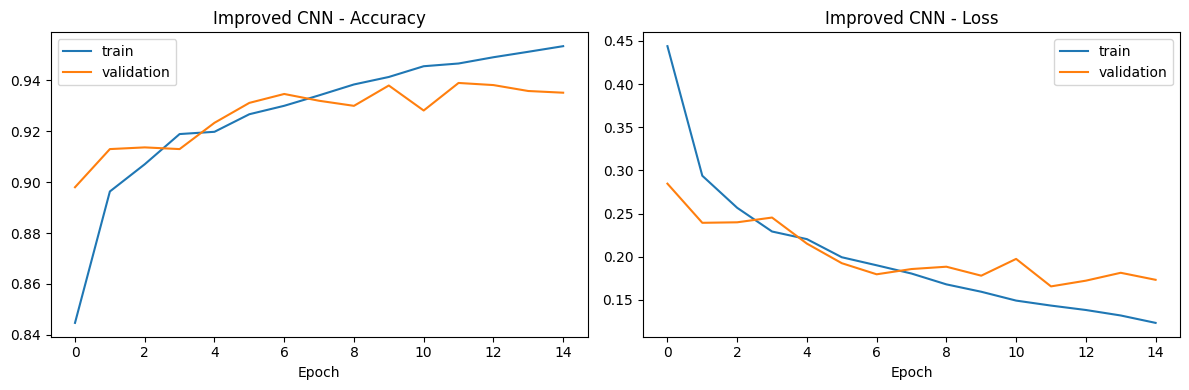

In [ ]:
def build_improved():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(10, activation="softmax"),
    ], name="improved_cnn")
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

improved = build_improved()
early_stop2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

hist_imp = improved.fit(x_train, y_train,
                        epochs=25, batch_size=64,
                        validation_split=0.1,
                        callbacks=[early_stop2], verbose=2)
plot_curves(hist_imp, "Improved CNN")

In [ ]:
def summarize(model, name):
    loss, acc = model.evaluate(x_test, y_test, verbose=0)
    preds = np.argmax(model.predict(x_test, verbose=0), axis=1)
    rep = classification_report(y_test, preds, target_names=CLASS_NAMES, output_dict=True)
    f1s = {c: rep[c]["f1-score"] for c in CLASS_NAMES}
    worst = min(f1s, key=f1s.get)
    return {"Model": name,
            "Parameters": model.count_params(),
            "Test accuracy": round(acc, 4),
            "Test loss": round(loss, 4),
            "Macro F1": round(rep["macro avg"]["f1-score"], 4),
            "Weakest class": worst,
            "Weakest class F1": round(f1s[worst], 3)}

comparison = pd.DataFrame([summarize(baseline, "Baseline CNN"),
                           summarize(improved, "Improved CNN")])
comparison

,Model,Parameters,Test accuracy,Test loss,Macro F1,Weakest class,Weakest class F1
0,Baseline CNN,421642,0.9181,0.2480,0.9177,Shirt,0.765
1,Improved CNN,469098,0.9341,0.1972,0.9339,Shirt,0.800


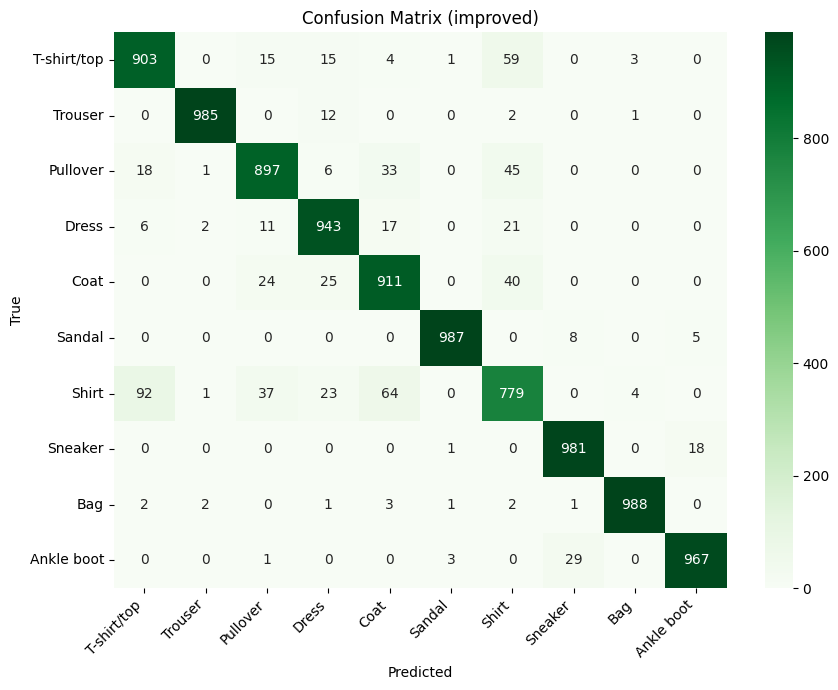

In [ ]:

y_pred_imp = np.argmax(improved.predict(x_test, verbose=0), axis=1)
cm2 = confusion_matrix(y_test, y_pred_imp)
plt.figure(figsize=(9, 7))
sns.heatmap(cm2, annot=True, fmt="d", cmap="Greens",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix (improved)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
improved.save("fashion_mnist_cnn.keras")
print("Saved: fashion_mnist_cnn.keras")

Saved: fashion_mnist_cnn.keras
